# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
Missing values: 0
Duplicate rows: 0
                          count           mean           std      min  \
age                       299.0      60.833893     11.894809     40.0   
anaemia                   299.0       0.431438      0.496107      0.0   
creatinine_phosphokinase  299.0     581.839465    970.287881     23.0   
diabetes                  299.0       0.418060      0.494067      0.0   
ejection_fraction         299.0      38.083612     11.834841     14.0   
high_blood_pressure       299.0   

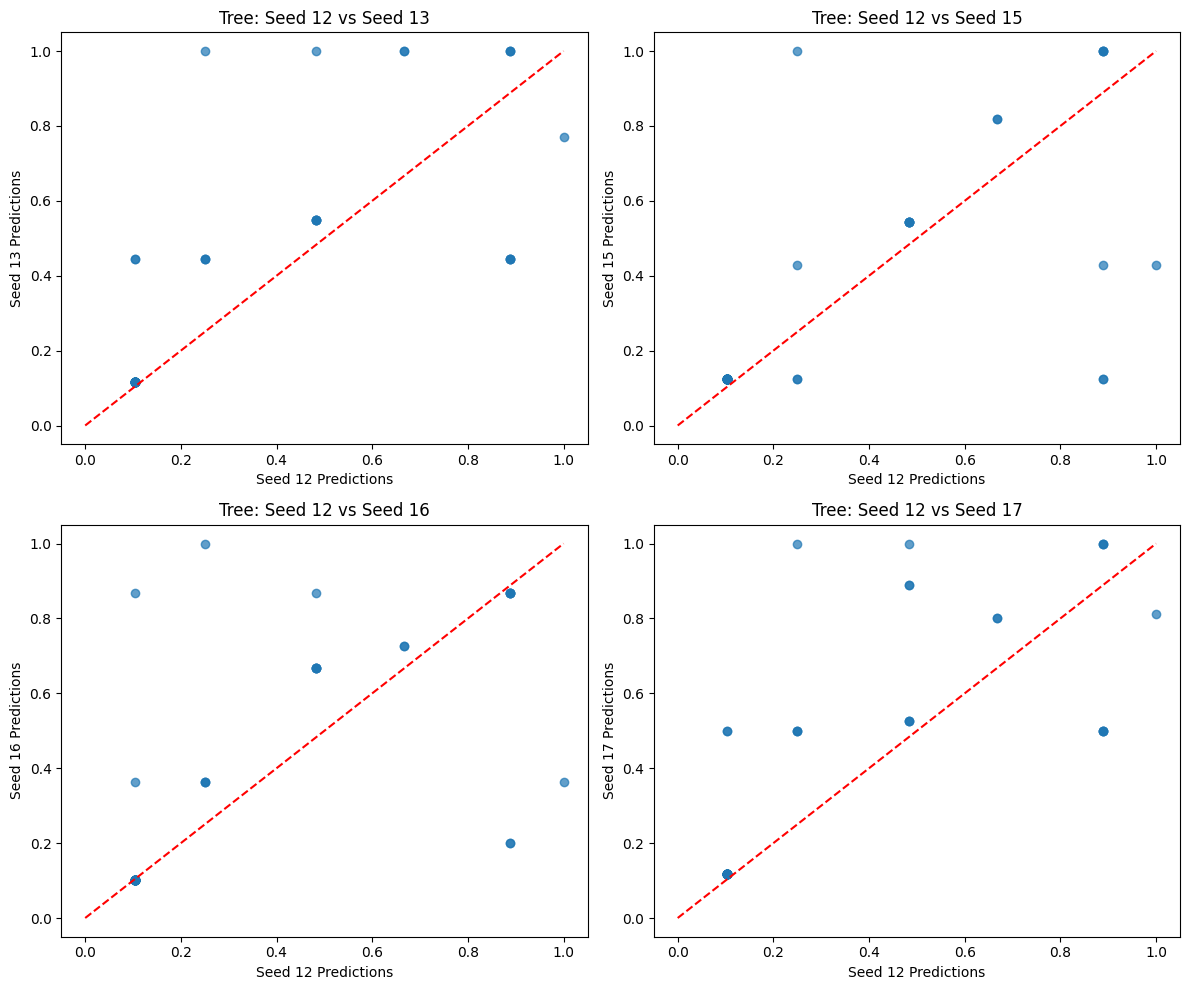

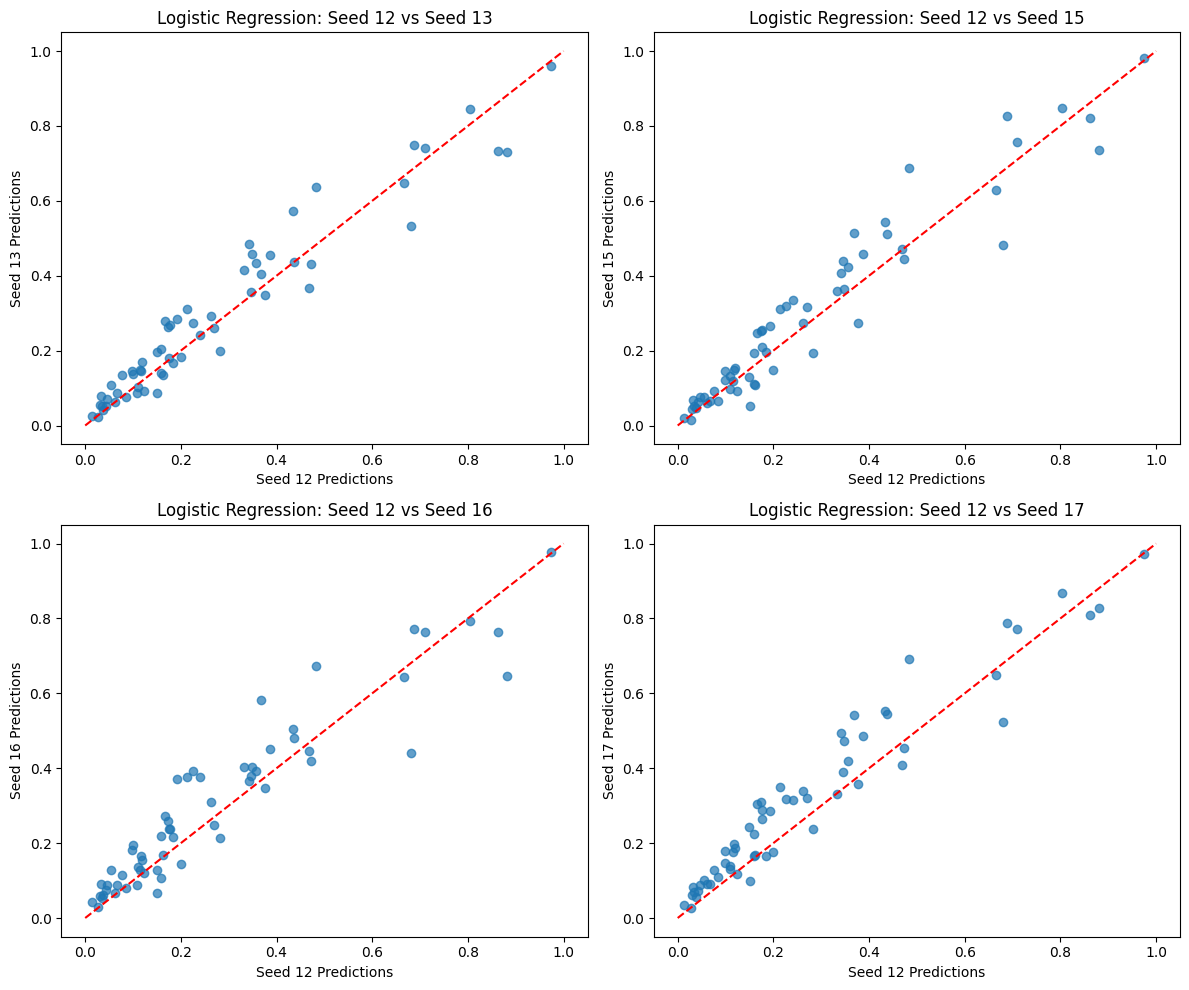

correlations
Seed 12 vs Seed 13: 0.7866
Seed 12 vs Seed 15: 0.7437
Seed 12 vs Seed 16: 0.7167
Seed 12 vs Seed 17: 0.7910

logistic reg correlations
Seed 12 vs Seed 13: 0.9641
Seed 12 vs Seed 15: 0.9610
Seed 12 vs Seed 16: 0.9419
Seed 12 vs Seed 17: 0.9636
tree regressions

Seed 12 vs Seed 13
Intercept: 0.086
Slope: 0.8274
R-squared: 0.6187

Seed 12 vs Seed 15
Intercept: 0.0766
Slope: 0.7284
R-squared: 0.5531

Seed 12 vs Seed 16
Intercept: 0.0926
Slope: 0.7456
R-squared: 0.5136

Seed 12 vs Seed 17
Intercept: 0.0951
Slope: 0.8468
R-squared: 0.6257

log regression regressions

Seed 12 vs Seed 13
Intercept: 0.0384
Slope: 0.9293
R-squared: 0.9295

Seed 12 vs Seed 15
Intercept: 0.026
Slope: 0.9771
R-squared: 0.9235

Seed 12 vs Seed 16
Intercept: 0.0567
Slope: 0.8954
R-squared: 0.8872

Seed 12 vs Seed 17
Intercept: 0.0579
Slope: 0.9556
R-squared: 0.9286
Coefficients across seeds:
                         12     13     15     16     17
age                   0.054  0.058  0.059  0.053  0.049
an

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score


URL = ("https://raw.githubusercontent.com/elijahschoeniger-cpu/L03-tree-stability/"
       "main/data/heart_failure/heart_failure_clinical_records_dataset.csv")

df = pd.read_csv(URL)

#1
print(df.shape)                      # (299, 13)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())   # 0
print("Duplicate rows:", df.duplicated().sum())   # 0
print(df.describe().T)

df = df.rename(columns={"DEATH_EVENT": "death_event"})

binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "death_event"]
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f"{c} has non-binary values"
    df[c] = df[c].astype(int)

# Two rows have age = 60.667
df["age"] = df["age"].round().astype(int)

# No NaNs, but the source filled gaps with summary stats:
#   platelets = 263358.03 (the column mean) in 25 rows
#   creatinine_phosphokinase = 582 in 47 rows with a suspicious spike at  median
df["platelets_imputed"] = np.isclose(df["platelets"], 263358.03).astype(int)
df["cpk_imputed"] = (df["creatinine_phosphokinase"] == 582).astype(int)

# patients who died were followed for less time median 44.5 vs 172 days, encodes the outcome rather than predicting it.
df = df.drop(columns="time")

# Log-transform because of the heavy right skew to help the linear model
df["log_cpk"] = np.log(df["creatinine_phosphokinase"])
df["log_serum_creatinine"] = np.log(df["serum_creatinine"])
df = df.drop(columns=["creatinine_phosphokinase", "serum_creatinine"])

df["platelets"] = df["platelets"] / 1000

X = df.drop(columns="death_event")
y = df["death_event"]

print(df.head())
print("Class balance:\n", y.value_counts(normalize=True))   # ~68% survived / 32% died


#Q2
print("Q2")


X = df.drop(columns="death_event")
y = df['death_event']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
logit = LogisticRegression(max_iter=5000).fit(X_train, y_train)

print("seed 12",
      "| tree accuracy:", round(tree.score(X_test, y_test), 3),
      "| logit accuracy:", round(logit.score(X_test, y_test), 3))
print(export_text(tree, feature_names=list(X.columns)))

tree_preds = {12: tree.predict_proba(X_test)[:, 1]}
logit_preds = {12: logit.predict_proba(X_test)[:, 1]}
logit_coefs = {12: logit.coef_[0]}

X_test_q2 = X_test

#Q3

for seed in [13, 15, 16, 17]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
    logit = LogisticRegression(max_iter=5000).fit(X_train, y_train)

    print("seed", seed,
          "| tree accuracy:", round(tree.score(X_test, y_test), 3),
          "| logit accuracy:", round(logit.score(X_test, y_test), 3))
    print(export_text(tree, feature_names=list(X.columns)))
    tree_preds[seed] = tree.predict_proba(X_test_q2)[:, 1]
    logit_preds[seed] = logit.predict_proba(X_test_q2)[:, 1]
    logit_coefs[seed] = logit.coef_[0]


tree_preds = pd.DataFrame(tree_preds)
logit_preds = pd.DataFrame(logit_preds)
print(pd.DataFrame(logit_coefs, index=X.columns).round(3))

#Question 4a


seeds = [13, 15, 16, 17]


fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(tree_preds[12], tree_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Tree: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()




fig, axes = plt.subplots(2, 2, figsize=(12, 10))


for ax, seed in zip(axes.flatten(), seeds):
   ax.scatter(logit_preds[12], logit_preds[seed], alpha=0.7)


   ax.plot([0, 1], [0, 1], 'r--')


   ax.set_title(f"Logistic Regression: Seed 12 vs Seed {seed}")
   ax.set_xlabel("Seed 12 Predictions")
   ax.set_ylabel(f"Seed {seed} Predictions")


plt.tight_layout()
plt.show()


#The decision tree predictions vary across different seeds, with many points far from the diagonal line.
#In comparison, the logistic regression predictions are much closer to the diagonal line.
#This shows that logistic regression is more consistent across different train-test splits, while decision trees are more sensitive to changes in the training data.




#Question 4b:


print("correlations")


for seed in seeds:
   corr = tree_preds[12].corr(tree_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")




print("\nlogistic reg correlations")


for seed in seeds:
   corr = logit_preds[12].corr(logit_preds[seed])
   print(f"Seed 12 vs Seed {seed}: {corr:.4f}")


#The decision tree correlations range from 0.7167 to 0.7910, while the logistic regression correlations range from 0.9419 to 0.9641.
#This shows that logistic regression predictions are more highly correlated across different seeds, and they are more consistent.
#Decision tree predictions vary more depending on the training data.








#Question 4c


from scipy.stats import linregress


print("tree regressions")


for seed in seeds:
   result = linregress(tree_preds[12], tree_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))




# Logistic regression regressions


print("\nlog regression regressions")


for seed in seeds:
   result = linregress(logit_preds[12], logit_preds[seed])


   print(f"\nSeed 12 vs Seed {seed}")
   print("Intercept:", round(result.intercept, 4))
   print("Slope:", round(result.slope, 4))
   print("R-squared:", round(result.rvalue**2, 4))


#The linear models appear to have more consistent coefficients and predictions across different train-test splits.
#Decision trees are more sensitive to changes in the training data, resulting in different tree structures and predictions.
#Overall, logistic regression is more stable than decision trees.








# Question 5


coef_df = pd.DataFrame(logit_coefs, index=X.columns)


print("Coefficients across seeds:")
print(coef_df.round(3))


print("\nStdev of coefficients across seeds:")
print(coef_df.std(axis=1).round(4))


print("\nRange of coefficients across seeds:")
print((coef_df.max(axis=1) - coef_df.min(axis=1)).round(4))


#Linear models have more consistent coefficients and predictions across different train-test splits, but some coefficients vary more than others.
#Age and ejection fraction have  small standard deviations, while anaemia and high blood pressure vary more.
#Decision trees are more sensitive to changes in the training data, result in different tree structures and predictions.
#Overall, logistic regression appears to be more stable than decision trees.





## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]